# LIB, SB and SBE frequencies: our B vs MHW

Winter frequencies from our daily B (`B Value Computation.ipynb`) against the curves digitised from MHW Fig. 2 (`MHW` in `plot_sbe_frequency.py`).

In [7]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from plot_sbe_frequency import MHW   # fractions of days at longitudes 0, 5, ..., 355

B_daily = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_TH08.parquet").rename(columns=int)
WINTERS = range(1958, 2002)   # DJF 1957/58 - 2000/01, as in MHW, labelled by January
lons = B_daily.columns.to_numpy()
B_winters = [B_daily.loc[f"{y-1}-12":f"{y}-02"].to_numpy() for y in WINTERS]

LIB: B > 0. SB: LIB at 3 neighbouring longitudes inside the 45° sector centred on that longitude. SBE: SB on that day and the 4 days before it (as MHW count it).

In [8]:
def blocking_flags(B):
    """B: (days, longitudes) for one winter -> LIB, SB, SBE as boolean arrays."""
    lib = B > 0
    run = lib & np.roll(lib, 1, axis=1) & np.roll(lib, -1, axis=1)   # centre of 3 LIB longitudes in a row
    sb = np.zeros_like(lib)
    for k in range(-3, 4):          # run centre within 15°, so all 3 points lie in the sector L-20 ... L+20
        sb |= np.roll(run, k, axis=1)
    fwd = np.zeros(sb.shape, int)   # number of consecutive SB days up to and including each day
    for t in range(len(sb)):
        fwd[t] = sb[t] * (fwd[t - 1] + 1 if t > 0 else 1)
    return lib, sb, fwd >= 5

flags = [blocking_flags(B) for B in B_winters]
ours = {name: np.concatenate([f[i] for f in flags]).mean(axis=0) for i, name in enumerate(["LIB", "SB", "SBE"])}

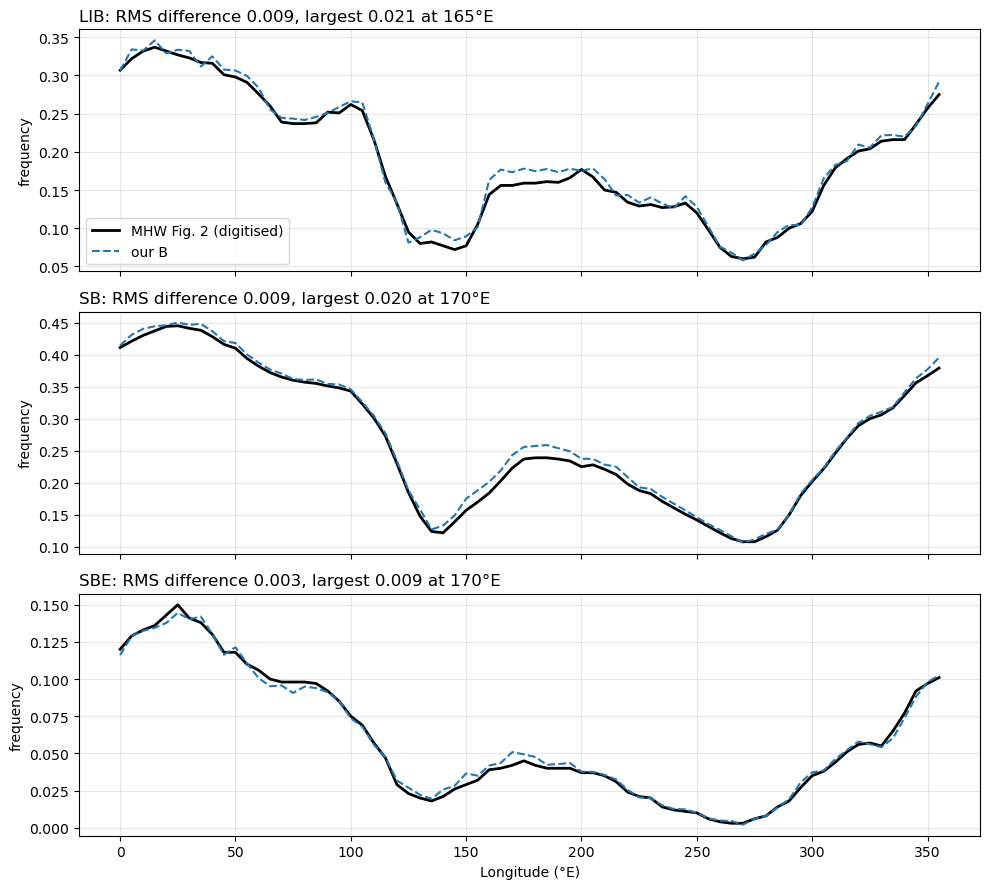

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, measure in zip(axes, ["LIB", "SB", "SBE"]):
    diff = ours[measure] - MHW[measure]
    ax.plot(lons, MHW[measure], color="black", linewidth=2, label="MHW Fig. 2 (digitised)")
    ax.plot(lons, ours[measure], color="tab:blue", linestyle="--", label="our B")
    ax.set_ylabel("frequency")
    ax.set_title(f"{measure}: RMS difference {np.sqrt(np.mean(diff**2)):.3f}, largest {np.abs(diff).max():.3f} "
                 f"at {lons[np.abs(diff).argmax()]}°E", loc="left")
    ax.grid(alpha=0.3)
axes[0].legend()
axes[-1].set_xlabel("Longitude (°E)")
plt.tight_layout()
plt.show()